## 🐦 Bird Challenge — Deployment Metadata

Once project data and deployment metadata are uploaded from ODK, audio recordings are processed through the BirdNET classifier, which assigns confidence scores to detected species across audio segments.
Because human validation of every prediction is impractical, Natural State uses ornithologist-validated clips to calibrate the relationship between BirdNET confidence and prediction correctness for each species.
Using the fitted species-specific calibration curves, a confidence threshold corresponding to **≥99% probability of correctness** is calculated and used to classify predictions as `observation = True` or `False`.
The resulting calibration parameters, thresholds, validation rules, and processing logic can then be provided to the Tech team for automated implementation on the **NS Analytics** platform.


In [57]:
# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================
# pandas is used for loading, inspecting, cleaning and merging
# tabular data.
import pandas as pd
import os


# ============================================================
# 2. DEFINE THE DATA FOLDER
# ============================================================
# This is the folder containing the Natural State BirdNET files.
data_folder = r"C:\Users\HP\Downloads\Take Home Project\Data Birds"


# ============================================================
# 3. DEFINE THE TWO INPUT FILES
# ============================================================
# IMPORTANT:
# Replace these filenames with the exact names of your two files
# if they are different.
birdnet_predictions_path = os.path.join(
    data_folder,
    "birdnet_predictions.csv"
)

birdnet_validation_path = os.path.join(
    data_folder,
    "validation_results.csv"
)


# ============================================================
# 4. CHECK THAT THE FILES EXIST BEFORE READING THEM
# ============================================================
# This prevents a confusing FileNotFoundError later.
print("Checking input files...\n")

print(
    "BirdNET predictions file exists:",
    os.path.exists(birdnet_predictions_path)
)

print(
    "BirdNET validation file exists:",
    os.path.exists(birdnet_validation_path)
)


# ============================================================
# 5. LOAD THE TWO DATASETS
# ============================================================
# The predictions file contains BirdNET's predictions and
# confidence scores for the audio clips.
birdnet_predictions = pd.read_csv(birdnet_predictions_path)

# The validation file contains a subset of predictions that were
# checked by a human ornithologist. The 'outcome' field tells us
# whether the BirdNET prediction was correct.
birdnet_validation = pd.read_csv(birdnet_validation_path)


# ============================================================
# 6. CONFIRM THE DATASET SIZES
# ============================================================
# shape returns:
# (number of rows, number of columns)
#
# This gives us an immediate check that the files loaded correctly.
print("\n================ DATASET SIZES ================\n")

print(
    "BirdNET predictions:",
    birdnet_predictions.shape
)

print(
    "BirdNET validation:",
    birdnet_validation.shape
)


# ============================================================
# 7. DISPLAY THE COLUMN NAMES
# ============================================================
# Before merging, we need to understand exactly what fields
# are available in each dataset.
print("\n================ PREDICTION COLUMNS ================\n")

print(birdnet_predictions.columns.tolist())

print("\n================ VALIDATION COLUMNS ================\n")

print(birdnet_validation.columns.tolist())


# ============================================================
# 8. DISPLAY A FEW RECORDS FROM EACH DATASET
# ============================================================
# This allows us to visually confirm that the data look as
# expected before doing any transformation or merge.
print("\n================ BIRDNET PREDICTIONS SAMPLE ================\n")

display(birdnet_predictions.head())


print("\n================ ORNITHOLOGIST VALIDATION SAMPLE ================\n")

display(birdnet_validation.head())


# ============================================================
# 9. CHECK DATA TYPES
# ============================================================
# We especially care about:
# - confidence: BirdNET confidence score
# - outcome: human validation result (0 = incorrect, 1 = correct)
#
# We inspect the types before modelling because statistical
# models require numeric values for these variables.
print("\n================ PREDICTION DATA TYPES ================\n")

print(birdnet_predictions.dtypes)


print("\n================ VALIDATION DATA TYPES ================\n")

print(birdnet_validation.dtypes)


# ============================================================
# 10. CHECK FOR MISSING VALUES
# ============================================================
# Missing values could affect the merge and later logistic
# regression analysis.
print("\n================ MISSING VALUES: PREDICTIONS ================\n")

print(
    birdnet_predictions.isna().sum()
)


print("\n================ MISSING VALUES: VALIDATION ================\n")

print(
    birdnet_validation.isna().sum()
)



Checking input files...

BirdNET predictions file exists: True
BirdNET validation file exists: True

================ DATASET SIZES ================

BirdNET predictions: (29491, 13)
BirdNET validation: (551, 6)

================ PREDICTION COLUMNS ================

['selection', 'view', 'channel', 'begin_time_s', 'end_time_s', 'low_freq_hz', 'high_freq_hz', 'common_name', 'species_code', 'confidence', 'begin_path', 'file_offset_s', 'folder']

================ VALIDATION COLUMNS ================

['scientificName', 'commonName', 'vBirdNET', 'filename', 'confidence', 'outcome']

================ BIRDNET PREDICTIONS SAMPLE ================



,selection,view,channel,begin_time_s,end_time_s,low_freq_hz,high_freq_hz,common_name,species_code,confidence,begin_path,file_offset_s,folder
0,1,Spectrogram 1,1,889,892,0,15000,African Black-headed Oriole,abhori1,0.6278,Grid2/RBS02/RBS02_20230622_170000.WAV,889,RBS02
1,2,Spectrogram 1,1,1084,1087,0,15000,African Black-headed Oriole,abhori1,0.3217,Grid2/RBS02/RBS02_20230622_170000.WAV,1084,RBS02
2,1,Spectrogram 1,1,3178,3181,0,15000,Abyssinian Nightjar,abynig1,0.1028,Grid2/RBS02/RBS02_20230622_190000.WAV,3178,RBS02
3,2,Spectrogram 1,1,3574,3577,0,15000,Abyssinian Nightjar,abynig1,0.1456,Grid2/RBS02/RBS02_20230622_190000.WAV,3574,RBS02
4,1,Spectrogram 1,1,1533,1536,0,15000,Abyssinian Nightjar,abynig1,0.1129,Grid2/RBS02/RBS02_20230623_190000.WAV,1533,RBS02



================ ORNITHOLOGIST VALIDATION SAMPLE ================



,scientificName,commonName,vBirdNET,filename,confidence,outcome
0,Caprimulgus poliocephalus,Abyssinian Nightjar,v2.4,0.107_4_RBS21_20230630_190000.wav,0.107,1
1,Caprimulgus poliocephalus,Abyssinian Nightjar,v2.4,0.109_1_RBS14_20230706_010000.wav,0.109,1
2,Caprimulgus poliocephalus,Abyssinian Nightjar,v2.4,0.110_1_RBS60_20230702_220000.wav,0.110,1
3,Caprimulgus poliocephalus,Abyssinian Nightjar,v2.4,0.113_3_RBS14_20230708_040002.wav,0.113,1
4,Caprimulgus poliocephalus,Abyssinian Nightjar,v2.4,0.116_1_RBS55_20230701_220000.wav,0.116,1



================ PREDICTION DATA TYPES ================

selection          int64
view              object
channel            int64
begin_time_s       int64
end_time_s         int64
low_freq_hz        int64
high_freq_hz       int64
common_name       object
species_code      object
confidence       float64
begin_path        object
file_offset_s      int64
folder            object
dtype: object

================ VALIDATION DATA TYPES ================

scientificName     object
commonName         object
vBirdNET           object
filename           object
confidence        float64
outcome             int64
dtype: object

================ MISSING VALUES: PREDICTIONS ================

selection        0
view             0
channel          0
begin_time_s     0
end_time_s       0
low_freq_hz      0
high_freq_hz     0
common_name      0
species_code     0
confidence       0
begin_path       0
file_offset_s    0
folder           0
dtype: int64

================ MISSING VALUES: VALIDATION ======

In [58]:
# ============================================================
  # SPLIT VALIDATION DATA BY SPECIES
# ============================================================

# Check the species represented in the validation dataset
print("Species in validation dataset:")
print(birdnet_validation['commonName'].unique())

# Count how many validation records we have for each species
print("\nNumber of validation records per species:")
print(birdnet_validation['commonName'].value_counts())

Species in validation dataset:
['Abyssinian Nightjar' 'African Black-headed Oriole'
 'Red-billed Firefinch' 'Three-banded Plover']

Number of validation records per species:
commonName
Abyssinian Nightjar            150
African Black-headed Oriole    150
Three-banded Plover            150
Red-billed Firefinch           101
Name: count, dtype: int64


In [59]:
# ============================================================
# STEP 1: GET UNIQUE SPECIES FROM commonName
# ============================================================

species_names = birdnet_validation['commonName'].dropna().unique()

print("Species found:")
print(species_names)

Species found:
['Abyssinian Nightjar' 'African Black-headed Oriole'
 'Red-billed Firefinch' 'Three-banded Plover']


In [60]:
# ============================================================
# STEP 2: SPLIT VALIDATION DATA BY SPECIES
# ============================================================

species_data = {}

for species in species_names:

    # Create a separate dataframe for each species
    species_data[species] = birdnet_validation[
        birdnet_validation['commonName'] == species
    ].copy()

    print(
        f"{species}: "
        f"{len(species_data[species])} validation records"
    )

Abyssinian Nightjar: 150 validation records
African Black-headed Oriole: 150 validation records
Red-billed Firefinch: 101 validation records
Three-banded Plover: 150 validation records


In [61]:
import numpy as np

def logit(p):
    return np.log(p / (1 - p))

for species, data in species_data.items():

    # Avoid logit(0) and logit(1)
    confidence = data['confidence'].clip(1e-6, 1 - 1e-6)

    data['logit_confidence'] = logit(confidence)

In [62]:
for species, data in species_data.items():
    print(
        species,
        "infinite values:",
        np.isinf(data['logit_confidence']).sum()
    )

Abyssinian Nightjar infinite values: 0
African Black-headed Oriole infinite values: 0
Red-billed Firefinch infinite values: 0
Three-banded Plover infinite values: 0


In [63]:
from sklearn.linear_model import LogisticRegression

models = {}

for species, data in species_data.items():

    X = data[['logit_confidence']]
    y = data['outcome']

    if y.nunique() < 2:
        print(f"Skipping {species}: only one outcome class")
        continue

    model = LogisticRegression(
        penalty=None,
        solver='lbfgs',
        max_iter=1000
    )

    model.fit(X, y)

    models[species] = model

    print(f"\n{species}")
    print(f"Intercept: {model.intercept_[0]:.4f}")
    print(f"Slope:     {model.coef_[0][0]:.4f}")


Abyssinian Nightjar
Intercept: 3.1591
Slope:     2.0723
Skipping African Black-headed Oriole: only one outcome class

Red-billed Firefinch
Intercept: -1.4594
Slope:     0.9417

Three-banded Plover
Intercept: 5.1700
Slope:     0.5474


In [64]:
def logit(p):
    return np.log(p / (1 - p))

target_probability = 0.99
target_logit = logit(target_probability)

thresholds = []

for species, model in models.items():

    intercept = model.intercept_[0]
    slope = model.coef_[0][0]

    # Solve for the logit-confidence value
    x_99 = (target_logit - intercept) / slope

    # Convert back to original BirdNET confidence scale
    confidence_99 = 1 / (1 + np.exp(-x_99))

    thresholds.append({
        'commonName': species,
        'intercept': intercept,
        'slope': slope,
        'logit_threshold_99': x_99,
        'confidence_threshold_99': confidence_99
    })

thresholds = pd.DataFrame(thresholds)

thresholds

,commonName,intercept,slope,logit_threshold_99,confidence_threshold_99
0,Abyssinian Nightjar,3.159088,2.072290,0.692969,0.666627
1,Red-billed Firefinch,-1.459424,0.941674,6.429557,0.998389
2,Three-banded Plover,5.169958,0.547420,-1.050086,0.259209


Loaded validation data: (551, 6)
Species present: 4
Usable validation records: 551
Outcome counts:
outcome
0    129
1    422
Name: count, dtype: int64
Skipping African Black-headed Oriole: only one outcome class is present.

--- Model-estimated 99% Correctness Thresholds ---
          commonName  n_observations  n_incorrect  n_correct  intercept  slope  observation_threshold_99       threshold_status
 Abyssinian Nightjar             150           33        117     3.1591 2.0723                    0.6666  Within observed range
Red-billed Firefinch             101           95          6    -1.4594 0.9417                    0.9984 Outside observed range
 Three-banded Plover             150            1        149     5.1700 0.5474                    0.2592  Within observed range
Red-billed Firefinch: estimated 99% threshold 0.9984 is outside the observed confidence range; it involves extrapolation.


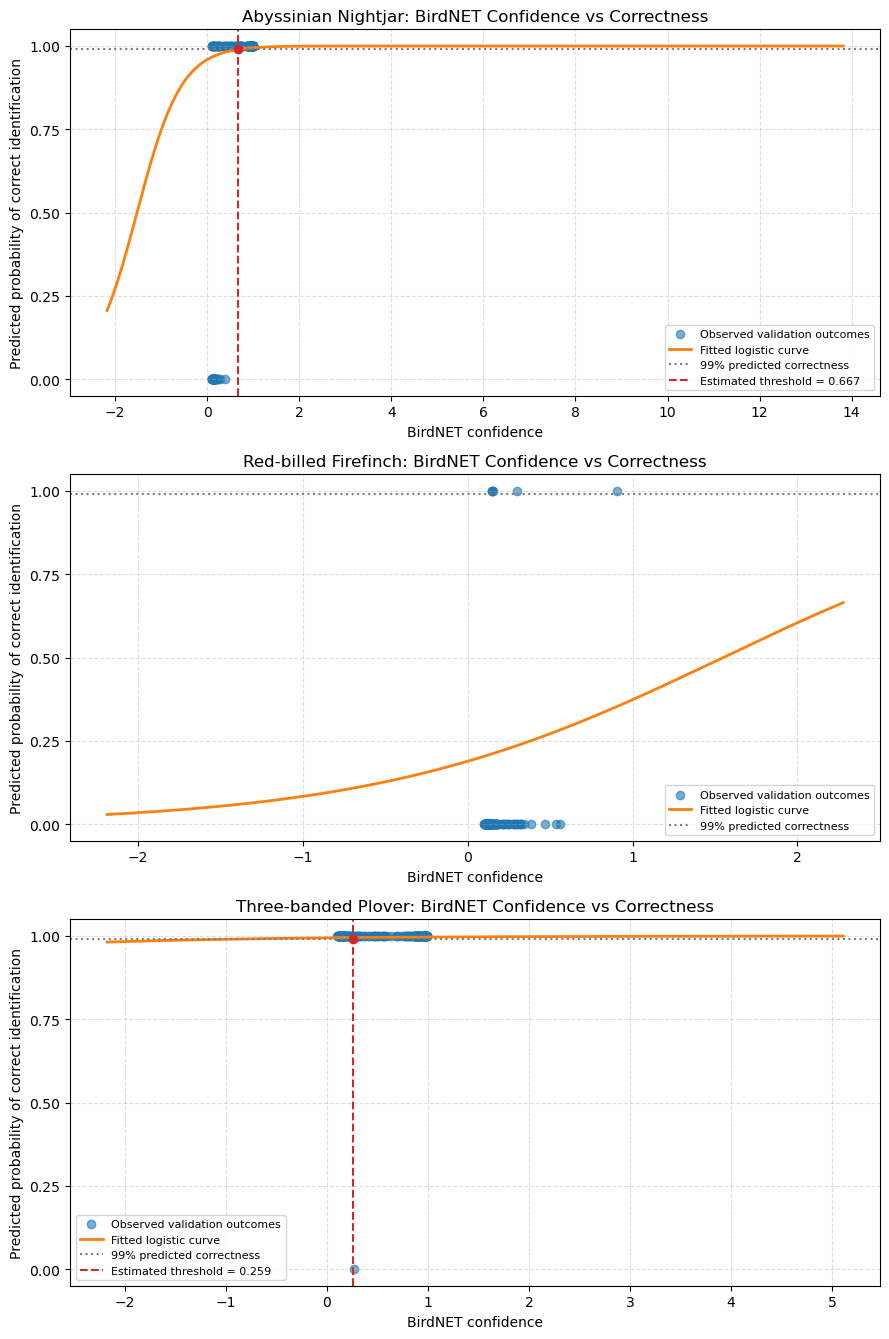


INTERPRETATION
The fitted curve estimates the probability of a correct BirdNET identification at each confidence level.
The 99% threshold is the confidence at which the fitted model predicts 99% correctness, where an increasing threshold exists.
This is not proof of 99% empirical precision. Evaluate threshold performance on independent held-out validation data before claiming that precision is at least 99%.


In [1]:

# ============================================================
# BIRDNET CONFIDENCE VS PREDICTION CORRECTNESS
# Species-specific logistic regression and 99% thresholds
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from scipy.special import expit

# ============================================================
# 1. LOAD VALIDATION DATA
# ============================================================

df = pd.read_csv(
    r'C:\Users\HP\Downloads\Take Home Project\Data Birds\validation_results.csv'
)

print("Loaded validation data:", df.shape)
print("Species present:", df['commonName'].nunique())

# Retain rows with the fields needed for analysis
df = df.dropna(
    subset=['commonName', 'confidence', 'outcome']
).copy()

# Ensure confidence and outcome are numeric
df['confidence'] = pd.to_numeric(
    df['confidence'], errors='coerce'
)

df['outcome'] = pd.to_numeric(
    df['outcome'], errors='coerce'
)

# Remove invalid or missing values
df = df.dropna(
    subset=['confidence', 'outcome']
).copy()

# Outcome must be binary: 0 = incorrect, 1 = correct
df = df[df['outcome'].isin([0, 1])].copy()

# Confidence must be a valid probability
df = df[
    df['confidence'].between(0, 1)
].copy()

df['outcome'] = df['outcome'].astype(int)

print("Usable validation records:", len(df))
print("Outcome counts:")
print(df['outcome'].value_counts().sort_index())

# ============================================================
# 2. DEFINE LOGIT TRANSFORMATION
# ============================================================

def logit(p):
    """
    Convert probabilities to log-odds.
    Clipping avoids log(0) and division by zero.
    """
    p = np.asarray(p, dtype=float)
    p_clipped = np.clip(p, 1e-6, 1 - 1e-6)

    return np.log(p_clipped / (1 - p_clipped))


# Transform original BirdNET confidence ONCE
df['logit_confidence'] = logit(df['confidence'])

# Target predicted probability of correctness
target_probability = 0.99
target_logit = logit(target_probability)

# ============================================================
# 3. FIT SPECIES-SPECIFIC LOGISTIC REGRESSION MODELS
# ============================================================

species_names = df['commonName'].unique()

models = {}
thresholds = []

for species in species_names:

    sub = df[df['commonName'] == species].copy()

    # Both incorrect and correct outcomes are required
    if sub['outcome'].nunique() < 2:
        print(
            f"Skipping {species}: "
            "only one outcome class is present."
        )
        continue

    X = sub[['logit_confidence']]
    y = sub['outcome']

    # Warn about sparse outcome classes
    if y.value_counts().min() < 5:
        print(
            f"Warning: {species} has fewer than "
            "5 observations in at least one outcome class."
        )

    # Fit logistic regression
    model = LogisticRegression(
        penalty=None,
        solver='lbfgs',
        max_iter=1000
    )

    model.fit(X, y)
    models[species] = model

    intercept = model.intercept_[0]
    slope = model.coef_[0][0]

    # Solve for the logit-confidence value where
    # predicted probability of correctness = 0.99
    #
    # logit(P) = intercept + slope * logit(confidence)

    if slope > 1e-6:

        z_99 = (target_logit - intercept) / slope

        # Convert logit-confidence back to probability scale
        conf_99 = expit(z_99)

        # Is the threshold within observed data?
        observed_min = sub['confidence'].min()
        observed_max = sub['confidence'].max()

        if observed_min <= conf_99 <= observed_max:
            threshold_status = 'Within observed range'
        else:
            threshold_status = 'Outside observed range'

    else:
        # No increasing-confidence cutoff is supported
        # when the fitted slope is zero or negative.
        conf_99 = np.nan
        threshold_status = (
            'No increasing 99% threshold: '
            'slope is non-positive'
        )

    thresholds.append({
        'commonName': species,
        'n_observations': len(sub),
        'n_incorrect': int((y == 0).sum()),
        'n_correct': int((y == 1).sum()),
        'intercept': intercept,
        'slope': slope,
        'observation_threshold_99': conf_99,
        'threshold_status': threshold_status
    })


# ============================================================
# 4. DISPLAY THRESHOLD RESULTS
# ============================================================

threshold_df = pd.DataFrame(thresholds)

print(
    "\n--- Model-estimated 99% Correctness Thresholds ---"
)

if not threshold_df.empty:

    print(
        threshold_df.to_string(
            index=False,
            float_format=lambda x: f'{x:.4f}'
        )
    )

    threshold_df.to_csv(
        'birdnet_logistic_thresholds.csv',
        index=False
    )

else:
    print("No eligible species models were fitted.")


# ============================================================
# 5. PLOT VALIDATION OUTCOMES AND FITTED CURVES
# ============================================================

if not models:

    print(
        "No plots generated: no species had both "
        "correct and incorrect validation outcomes."
    )

else:

    fig, axes = plt.subplots(
        nrows=len(models),
        ncols=1,
        figsize=(9, 4.5 * len(models)),
        squeeze=False
    )

    axes = axes.flatten()

    for idx, (species, model) in enumerate(models.items()):

        ax = axes[idx]

        sub = df[
            df['commonName'] == species
        ].copy()

        # ----------------------------------------------------
        # A. Observed validation outcomes
        # ----------------------------------------------------

        ax.scatter(
            sub['confidence'],
            sub['outcome'],
            alpha=0.6,
            color='tab:blue',
            label='Observed validation outcomes'
        )

        # ----------------------------------------------------
        # B. Generate original-scale confidence values
        # ----------------------------------------------------

        confidence_min = sub['confidence'].min()
        confidence_max = sub['confidence'].max()

        if confidence_min == confidence_max:

            print(
                f"Warning: {species} has no confidence "
                "variation; skipping its fitted curve."
            )

        else:

            # These are ORIGINAL BirdNET probabilities,
            # not logit-transformed values.
            x_vals = np.linspace(
                confidence_min,
                confidence_max,
                300
            )

            # Transform once to match model training
            x_logit = pd.DataFrame({
                'logit_confidence': logit(x_vals)
            })

            # Predicted probability that identification is correct
            y_prob = model.predict_proba(
                x_logit
            )[:, 1]

            # Plot original confidence against predicted probability
            ax.plot(
                #x_vals,
                x_logit,
                y_prob,
                color='tab:orange',
                linewidth=2,
                label='Fitted logistic curve'
            )

        # ----------------------------------------------------
        # C. Display the estimated 99% threshold
        # ----------------------------------------------------

        t_row = threshold_df[
            threshold_df['commonName'] == species
        ].iloc[0]

        c_99 = t_row['observation_threshold_99']

        if pd.notna(c_99):

            ax.axhline(
                target_probability,
                color='tab:gray',
                linestyle=':',
                label='99% predicted correctness'
            )

            if confidence_min <= c_99 <= confidence_max:

                ax.axvline(
                    c_99,
                    color='tab:red',
                    linestyle='--',
                    label=f'Estimated threshold = {c_99:.3f}'
                )

                ax.scatter(
                    [c_99],
                    [target_probability],
                    color='tab:red',
                    zorder=5
                )

            else:

                print(
                    f"{species}: estimated 99% threshold "
                    f"{c_99:.4f} is outside the observed "
                    "confidence range; it involves extrapolation."
                )

        # ----------------------------------------------------
        # D. Format plot
        # ----------------------------------------------------

        ax.set_title(
            f'{species}: BirdNET Confidence vs Correctness'
        )

        ax.set_xlabel('BirdNET confidence')
        ax.set_ylabel(
            'Predicted probability of correct identification'
        )

        ax.set_ylim(-0.05, 1.05)
        ax.set_yticks([
            0.00, 0.25, 0.50, 0.75, 1.00
        ])

        ax.legend(
            loc='best',
            fontsize=8
        )

        ax.grid(
            True,
            linestyle='--',
            alpha=0.4
        )

    plt.tight_layout()

    plt.savefig(
        'birdnet_logistic_thresholds.png',
        dpi=300,
        bbox_inches='tight'
    )

    plt.show()


# ============================================================
# 6. INTERPRETATION
# ============================================================

print("\nINTERPRETATION")
print(
    "The fitted curve estimates the probability of a "
    "correct BirdNET identification at each confidence level."
)
print(
    "The 99% threshold is the confidence at which the fitted "
    "model predicts 99% correctness, where an increasing "
    "threshold exists."
)
print(
    "This is not proof of 99% empirical precision. "
    "Evaluate threshold performance on independent "
    "held-out validation data before claiming that "
    "precision is at least 99%."
)

In [66]:
import pandas as pd

thresholds = pd.DataFrame(thresholds)

print(type(thresholds))
print(thresholds)

<class 'pandas.core.frame.DataFrame'>
             commonName  intercept     slope  observation_threshold_99
0   Abyssinian Nightjar   3.159088  2.072290                  0.666627
1  Red-billed Firefinch  -1.459424  0.941674                  0.998389
2   Three-banded Plover   5.169958  0.547420                  0.259209


In [67]:
# Copy the BirdNET predictions
results = birdnet_predictions.copy()

# Prepare the species-specific thresholds
threshold_lookup = thresholds[
    ['commonName', 'observation_threshold_99']
].copy()

# Rename the threshold column
threshold_lookup = threshold_lookup.rename(
    columns={'observation_threshold_99': 'threshold_99'}
)

# Merge using the different species-column names
results = results.merge(
    threshold_lookup,
    left_on='common_name',
    right_on='commonName',
    how='left'
)

# Check that thresholds were successfully matched
print(results[['common_name', 'confidence', 'threshold_99']].head(20))

                    common_name  confidence  threshold_99
0   African Black-headed Oriole      0.6278           NaN
1   African Black-headed Oriole      0.3217           NaN
2           Abyssinian Nightjar      0.1028      0.666627
3           Abyssinian Nightjar      0.1456      0.666627
4           Abyssinian Nightjar      0.1129      0.666627
5           Abyssinian Nightjar      0.1313      0.666627
6           Abyssinian Nightjar      0.1052      0.666627
7           Abyssinian Nightjar      0.1905      0.666627
8           Abyssinian Nightjar      0.2078      0.666627
9           Abyssinian Nightjar      0.2087      0.666627
10          Abyssinian Nightjar      0.1371      0.666627
11          Abyssinian Nightjar      0.2067      0.666627
12          Abyssinian Nightjar      0.1219      0.666627
13          Abyssinian Nightjar      0.2380      0.666627
14          Abyssinian Nightjar      0.3857      0.666627
15          Abyssinian Nightjar      0.1308      0.666627
16          Ab

In [68]:
print("Total predictions:", len(results))
print("Missing thresholds:", results['threshold_99'].isna().sum())
# Show the merged results

results['observation'] = (
    results['confidence'] >= results['threshold_99']
)



output_path = r"C:\Users\HP\Downloads\Take Home Project\Data Vegetation\outputs\birdnet_observation_results.csv"

results.to_csv(output_path, index=False)

print(f"Exported successfully to: {output_path}")


Total predictions: 29491
Missing thresholds: 18054


PermissionError: [Errno 13] Permission denied: 'C:\\Users\\HP\\Downloads\\Take Home Project\\Data Vegetation\\outputs\\birdnet_observation_results.csv'

In [69]:
results[
    ['common_name',
     'confidence',
     'threshold_99',
     'observation']
].head(20)

common_name_true_false = pd.crosstab(
    results['common_name'],
    results['observation']
)

common_name_true_false

observation,False,True
common_name,,
Abyssinian Nightjar,7040,3147
African Black-headed Oriole,18054,0
Red-billed Firefinch,235,0
Three-banded Plover,477,538


# 📋 Engineering Handover Memo: Automated BirdNET Calibration & Precision Filtering Pipeline

## 1. Objective & Context

Following the successful processing of raw audio recordings uploaded via field SD cards through the existing ML pipeline, this service will automatically ingest raw **BirdNET predictions**, apply validated statistical calibration models, and filter detections against a **target precision of ≥99%**, based on the calibration/validation data, before publication to analytics dashboards.

The proposed service sits downstream of the existing audio-to-ML pipeline and is responsible for:

**Ingest → Validate → Calibrate → Filter → Audit → Publish**

---

## 2. Input Data & Schema Requirements

The automation script expects the standard CSV output from the BirdNET ML inference engine:

`birdnet_predictions.csv`

### Required Fields

| Field                          | Description                                                                                               | Expected Type |
| ------------------------------ | --------------------------------------------------------------------------------------------------------- | ------------- |
| `begin_path` / `folder`        | Identifies the project grid, station, and source audio file, e.g. `Grid2/RBS02/RBS02_20230622_170000.WAV` | String        |
| `common_name` / `species_code` | Species taxonomy label predicted by BirdNET                                                               | String        |
| `confidence`                   | Raw BirdNET model confidence/probability score                                                            | Float         |
| `begin_time_s`                 | Start time of detection within the audio file                                                             | Float         |
| `end_time_s`                   | End time of detection within the audio file                                                               | Float         |

### Input Validation

Before calibration, the pipeline should:

* Validate that required columns are present.
* Enforce `confidence` as a numeric `float64` field.
* Check that confidence values fall within `[0, 1]`.
* Identify null or malformed confidence values.
* Quarantine invalid records rather than silently modifying or deleting them.

---

## 3. Core Algorithm & Mathematical Formulation

To correct for over- or under-confidence in raw BirdNET scores, the pipeline uses **logistic regression calibration models** fitted against human ornithologist validation data.

### Step A — Logit Transformation

Raw BirdNET confidence scores are transformed into **logit space**:

$$
\text{logit}(p) = \log\left(\frac{p}{1-p}\right)
$$

where:

* $p$ = raw BirdNET confidence
* $\text{logit}(p)$ = transformed confidence score

### Implementation Note

To prevent division by zero or infinite values, confidence scores should be clipped before transformation:

```python
confidence = confidence.clip(1e-6, 1 - 1e-6)
```

The transformed value can then be calculated as:

```python
logit_confidence = np.log(
    confidence / (1 - confidence)
)
```

---

### Step B — Calibrated Probability & 99% Threshold

For each species, a logistic calibration model estimates the probability that a BirdNET prediction is correct:

$$
P(Y=1|x)
=
\frac{1}
{1+e^{-(\beta_0+\beta_1x)}}
$$

where:

* $Y=1$ represents a correct BirdNET detection.
* $x$ represents the logit-transformed BirdNET confidence.
* $\beta_0$ is the fitted intercept.
* $\beta_1$ is the fitted slope.

For a target probability of correctness of **0.99**:

$$
\text{logit}(0.99)
=
\log\left(\frac{0.99}{0.01}\right)
\approx 4.595
$$

The required threshold in logit space is therefore:

$$
\text{Logit Threshold}_{99}
=
\frac{4.595-\beta_0}{\beta_1}
$$

---

### Step C — Back-Transformation to BirdNET Confidence

The logit threshold is converted back to the original BirdNET confidence scale:

$$
\text{Confidence Threshold}_{99}
=
\frac{1}
{1+e^{-\text{Logit Threshold}_{99}}}
$$

Each detection is then evaluated using:

```python
precision_filter_pass = confidence >= threshold_99
```

Only detections meeting the species-specific threshold are retained for publication.

---

## 4. Calibrated Model Parameters — Species Lookup Table

The following parameters, derived from empirical validation datasets, should be stored as a **configuration dictionary or database lookup table** within the automated service.

| Common Name                      | Intercept ($\beta_0$) | Slope ($\beta_1$) | Confidence Threshold for ≥99% Target Precision |
| -------------------------------- | --------------------: | ----------------: | ---------------------------------------------: |
| **Abyssinian Nightjar**          |                3.1591 |            2.0723 |                                     **0.6666** |
| **Red-billed Firefinch**         |               -1.4594 |            0.9417 |                                     **0.9984** |
| **Three-banded Plover**          |                5.1700 |            0.5474 |                                     **0.2592** |
| *Default / Uncalibrated Species* |                     — |                 — |                               *Fallback: 0.85* |

> **⚠️ Calibration rule:** Species with insufficient sample variation or extreme class imbalance should use a conservative high threshold until additional validation samples are available.

---

## 5. Automated Execution Workflow

The automated process should follow this sequence:

**SD Card Upload**
↓
**Existing ML / BirdNET Pipeline**
↓
**`birdnet_predictions.csv`**
↓
**Input Validation**
↓
**Confidence Clipping**
↓
**Logit Transformation**
↓
**Species Calibration Lookup**
↓
**99% Threshold Calculation / Application**
↓
**Precision Filtering**
↓
**PASS / FAIL Classification**
↓
**Audit Logging**
↓
**PostgreSQL / BigQuery**
↓
**NS Analytics**

### Step 1 — Trigger Event

The service is triggered automatically once the upstream ML pipeline has completed:

* SD card ingestion
* Audio processing
* BirdNET inference
* CSV generation

The calibration service should therefore **not be responsible for audio processing or BirdNET inference**.

### Step 2 — Data Ingestion

Load `birdnet_predictions.csv` into a memory-efficient pandas DataFrame.

### Step 3 — Batch Scoring & Filtering

For each prediction:

1. Validate the raw confidence score.
2. Apply confidence clipping.
3. Transform confidence into logit space.
4. Match the predicted species to the calibration lookup table.
5. Retrieve the species-specific intercept, slope and threshold.
6. Calculate/apply the 99% precision threshold.
7. Classify the detection as `PASS` or `FAIL`.

### Step 4 — Output Generation

Filtered high-confidence predictions should be written to the core database/data warehouse, such as:

* PostgreSQL
* BigQuery

These records will subsequently power the **NS Analytics** platform.

An audit record should also be generated showing:

* Total detections processed.
* Valid detections.
* Rejected/quarantined records.
* Retained detections.
* Retention rate.
* Results by species.
* Threshold applied to each species.

---

## 6. Edge Cases & Error Handling

### Missing / Unseen Species

If a predicted species is not present in the calibration lookup table:

1. Apply the conservative fallback threshold of `0.85`.
2. Set the calibration status to `fallback`.
3. Log a warning.
4. Retain the record in the processing/audit stream so that the species can be reviewed later.

Example:

```text
calibration_status = "fallback"
threshold_99 = 0.85
```

This prevents unseen species from silently bypassing the calibration process.

---

### Malformed or Missing Confidence Values

Confidence values must be validated before transformation.

The pipeline should:

* Enforce numeric `float64`.
* Identify null values.
* Identify non-numeric values.
* Validate the `[0,1]` range.
* Quarantine invalid records.
* Clip valid boundary values before logit transformation.

Invalid records should **not be silently corrected**, because doing so would make the processing history difficult to audit.

---

## 7. Recommended Output Data Contract

The published detection table should retain the original BirdNET information while adding calibration and QA fields.

Recommended additional fields include:

| Field                    | Purpose                                                       |
| ------------------------ | ------------------------------------------------------------- |
| `calibrated_probability` | Probability of correctness estimated by the calibration model |
| `threshold_99`           | Species-specific confidence threshold                         |
| `precision_filter_pass`  | Boolean indicating whether the detection passed the threshold |
| `calibration_status`     | Indicates calibrated species or fallback processing           |
| `model_version`          | Version of the calibration parameters used                    |
| `processing_timestamp`   | Time the record was processed                                 |
| `processing_batch_id`    | Identifier for the processing batch                           |

This creates a clear distinction between:

**Raw ML Prediction → Calibrated Result → Published Detection**

---

## 8. Auditability & Monitoring

Every processing batch should generate an audit record containing:

* Project ID
* Source file / batch ID
* Processing timestamp
* Total records received
* Valid records
* Quarantined records
* Retained records
* Rejected records
* Retention rate
* Species processed
* Species using calibrated models
* Species using fallback thresholds
* Threshold applied
* Calibration/model version
* Warnings and errors

This enables the technical team to monitor pipeline performance and reproduce how each published detection was generated.

---

## 9. Model & Configuration Versioning

Calibration parameters should be maintained separately from the application code.

For example:

```text
birdnet_calibration_v1.0
birdnet_calibration_v1.1
birdnet_calibration_v2.0
```

Each processed record should retain the `model_version` used.

When new ornithologist validation data becomes available, the calibration parameters can therefore be updated without changing the core processing logic.

Previous versions should be retained to ensure **reproducibility and auditability of historical results**.

---

## 10. Engineering Handover Summary

The existing ML pipeline is assumed to handle:

**SD Card → Audio Processing → BirdNET Inference → Raw Predictions**

The proposed automation service handles:

**Raw Predictions → QA → Calibration → 99% Precision Filtering → Audit → NS Analytics**

### Information Required by the Technical Team

The implementation specification therefore needs to define:

1. **Input schema** — expected BirdNET CSV structure.
2. **Calibration parameters** — species-specific intercepts and slopes.
3. **Thresholds** — calculated confidence thresholds.
4. **Fallback logic** — treatment of uncalibrated species.
5. **Transformation logic** — confidence → logit → calibrated probability.
6. **Filtering rule** — retain detections meeting the species-specific threshold.
7. **Output schema** — fields required by NS Analytics.
8. **QA rules** — handling of missing, malformed and invalid records.
9. **Audit requirements** — batch-level and species-level processing metrics.
10. **Model versioning** — version and retain calibration configurations.
11. **Automation trigger** — execute when the upstream ML pipeline produces a completed prediction file.
12. **Destination** — publish validated results to the NS Analytics data layer.

> **🔑 Key engineering principle:** Calibration parameters should be **configuration-driven rather than hard-coded into the processing script**. This allows the technical team to update species-specific calibration models independently, while preserving version history and reproducibility.
